# Have bike commutes over the Fremont Bridge come back since 2019?

**Summary.**

1. Riding over the Fremont Bridge is above 2019: 3,697 riders a day from January to September 2026, +8%.
2. Commuting is not back. The 6–10 am workday window is 19% below 2019; the gain is weekends (+36%) and off-peak workday hours (midday +37%, night +34%).
3. A drier 2026 doesn't explain it: on dry days alone, weekends are +35%, workdays +1%, and the 6–10 am window is still 19% below 2019.
4. The west/east sidewalk columns change meaning on 1 Jul 2025 (west share 66% to 31% overnight, totals unchanged). Don't use them across that date.

Open: what SDOT changed on 1 Jul 2025; whether the morning gap is closing (2025 to 2026 by month); public holidays, counted here as workdays; October onward when the data is published.

**Goal.** Seattle counts bikes crossing the Fremont Bridge every hour, and the bridge is a main commute route from the north end to downtown and South Lake Union. Find out whether riding, and commuting in particular, is back to 2019 levels.

9 Nov 2026 · Thomas with Claude · kernel cdp-node (TypeScript, cdp-kernel 0.8.0)

**Data.** Hourly counts: Seattle Open Data [65db-xm6k](https://data.seattle.gov/Transportation/Fremont-Bridge-Bicycle-Counter/65db-xm6k), fetched 9 Nov 2026. Loaders are in `fremont.ts` next to this notebook.

Recorded: ran in the shell, not in this kernel.

```sh
$ curl -sSfo data/fremont.csv "https://data.seattle.gov/api/views/65db-xm6k/rows.csv?accessType=DOWNLOAD" && wc -l data/fremont.csv && head -2 data/fremont.csv && tail -1 data/fremont.csv
```

```text
122676 data/fremont.csv
Date,"Fremont Bridge Sidewalks, south of N 34th St Total","Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk","Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk"
10/02/2012 01:00:00 PM,55,48,7
09/30/2026 11:00:00 PM,45,12,33
```


## 1. What does the counter cover?

Before comparing years, check which days and hours are there. A year with gaps would look like a drop in riding.

In [1]:
import * as pl from "npm:nodejs-polars@0.18.0";
import { hourly, daily, md } from "./fremont.ts";

const h = hourly();
const d = daily(h);
const coverage = d
  .groupBy("year")
  .agg(
    pl.col("day").count().alias("days"),
    pl.col("day").min().alias("first"),
    pl.col("day").max().alias("last"),
  )
  .join(
    h.groupBy("year").agg(pl.col("total").count().alias("hours")),
    { on: "year" },
  )
  .withColumns(pl.col("days").mul(24).minus(pl.col("hours")).alias("hours_missing"))
  .sort("year");
md(coverage)


| year | days | first | last | hours | hours_missing |
| --- | --- | --- | --- | --- | --- |
| 2012 | 91 | 2012-10-02 | 2012-12-31 | 2,171 | 13 |
| 2013 | 365 | 2013-01-01 | 2013-12-31 | 8,757 | 3 |
| 2014 | 365 | 2014-01-01 | 2014-12-31 | 8,759 | 1 |
| 2015 | 365 | 2015-01-01 | 2015-12-31 | 8,756 | 4 |
| 2016 | 366 | 2016-01-01 | 2016-12-31 | 8,783 | 1 |
| 2017 | 365 | 2017-01-01 | 2017-12-31 | 8,759 | 1 |
| 2018 | 365 | 2018-01-01 | 2018-12-31 | 8,759 | 1 |
| 2019 | 365 | 2019-01-01 | 2019-12-31 | 8,759 | 1 |
| 2020 | 366 | 2020-01-01 | 2020-12-31 | 8,783 | 1 |
| 2021 | 365 | 2021-01-01 | 2021-12-31 | 8,759 | 1 |
| 2022 | 365 | 2022-01-01 | 2022-12-31 | 8,759 | 1 |
| 2023 | 365 | 2023-01-01 | 2023-12-31 | 8,748 | 12 |
| 2024 | 366 | 2024-01-01 | 2024-12-31 | 8,783 | 1 |
| 2025 | 365 | 2025-01-01 | 2025-12-31 | 8,759 | 1 |
| 2026 | 273 | 2026-01-01 | 2026-09-30 | 6,551 | 1 |

**Coverage.** Every day from 2 Oct 2012 to 30 Sep 2026 is there. Each year misses one hour (the spring daylight-saving change); 2023 misses 12. No year has a gap big enough to move a yearly figure. 2026 ends on 30 Sep, so years are compared on **January to September** only: a full-year average would set 2026's summer against other years' winters.

## 2. Riders per day, by year

Average riders per day, January to September, each year against 2019.

In [2]:
const janSep = d.filter(pl.col("month").ltEq(9));
const byYear = janSep
  .groupBy("year")
  .agg(pl.col("total").mean().alias("per_day"))
  .sort("year");
const base2019 = byYear.filter(pl.col("year").eq(2019)).getColumn("per_day").get(0);
const yearly = byYear.withColumns(
  pl.col("per_day").div(base2019).minus(1).mul(100).alias("vs_2019_pct"),
);
md(yearly)


| year | per_day | vs_2019_pct |
| --- | --- | --- |
| 2013 | 2,726 | -21 |
| 2014 | 2,995 | -13 |
| 2015 | 2,941 | -14 |
| 2016 | 2,955 | -14 |
| 2017 | 2,826 | -18 |
| 2018 | 3,097 | -10 |
| 2019 | 3,430 | -0 |
| 2020 | 2,328 | -32 |
| 2021 | 2,161 | -37 |
| 2022 | 2,367 | -31 |
| 2023 | 2,661 | -22 |
| 2024 | 2,747 | -20 |
| 2025 | 3,073 | -10 |
| 2026 | 3,697 | 8 |

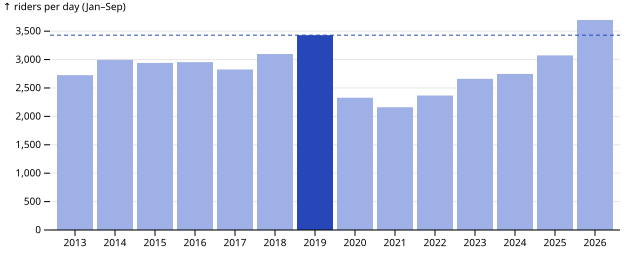

In [3]:
import * as Plot from "npm:@observablehq/plot@0.6.17";
import { parseHTML } from "npm:linkedom@0.18.9";
const { document } = parseHTML("<html></html>");

Plot.plot({
  document,
  width: 640,
  height: 260,
  marginLeft: 50,
  x: { label: null, tickFormat: "d" },
  y: { label: "riders per day (Jan–Sep)", grid: true },
  marks: [
    Plot.barY(yearly.toRecords(), {
      x: "year",
      y: "per_day",
      fill: (r) => (r.year === 2019 ? "#2747b8" : "#9fb0e6"),
    }),
    Plot.ruleY([base2019], { stroke: "#2747b8", strokeDasharray: "4 3" }),
    Plot.ruleY([0]),
  ],
})


**Finding 1 (revised after sections 3 to 6).** Riders are back, commuters are not. January to September 2026 averages 3,697 riders a day, 8% above 2019 (3,430) and the highest since the counter started. But the gain is weekends (+36%, finding 3) and off-peak workday hours (+37% midday), while the 6–10 am commute is still 19% below 2019 (finding 4). A drier year doesn't account for it (finding 5).

## 3. Can the sidewalk split separate commuters? (dead end)

Thomas asked whether the gain is commuters. The counter reports the west and east sidewalks separately, and riders heading downtown in the morning favour one side, so the split looked like a proxy for direction. Before relying on it: is the split stable over time?

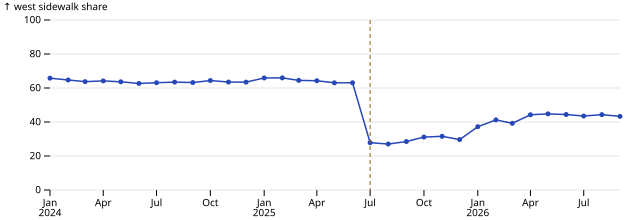

In [4]:
const split = h
  .filter(pl.col("day").gtEq(pl.lit("2024-01-01")))
  .withColumns(pl.col("day").str.slice(0, 7).alias("month_of"))
  .groupBy("month_of")
  .agg(pl.col("west").sum().div(pl.col("total").sum()).alias("west_share"))
  .sort("month_of");

Plot.plot({
  document,
  width: 640,
  height: 220,
  marginLeft: 50,
  x: { label: null },
  y: { label: "west sidewalk share", percent: true, domain: [0, 100], grid: true },
  marks: [
    Plot.lineY(split.toRecords(), { x: (r) => new Date(`${r.month_of}-01`), y: "west_share", stroke: "#2747b8", marker: "dot" }),
    Plot.ruleX([new Date("2025-07-01")], { stroke: "#94600a", strokeDasharray: "4 3" }),
  ],
})


In [5]:
md(
  h.filter(pl.col("day").gtEq(pl.lit("2025-06-27")).and(pl.col("day").ltEq(pl.lit("2025-07-03"))))
    .groupBy("day")
    .agg(pl.col("west").sum(), pl.col("east").sum(), pl.col("total").sum())
    .sort("day")
    .withColumns(pl.col("west").div(pl.col("total")).mul(100).alias("west_pct")),
)


| day | west | east | total | west_pct |
| --- | --- | --- | --- | --- |
| 2025-06-27 | 2,261 | 1,220 | 3,481 | 65 |
| 2025-06-28 | 2,520 | 1,868 | 4,388 | 57 |
| 2025-06-29 | 2,325 | 1,900 | 4,225 | 55 |
| 2025-06-30 | 3,127 | 1,635 | 4,762 | 66 |
| 2025-07-01 | 1,431 | 3,248 | 4,679 | 31 |
| 2025-07-02 | 1,359 | 3,150 | 4,509 | 30 |
| 2025-07-03 | 887 | 2,094 | 2,981 | 30 |

**Finding 2 (data quality).** The split is not usable across 1 Jul 2025. Overnight, the west sidewalk's share fell from 66% (30 Jun) to 31% (1 Jul), while the daily total carried on unchanged (4,762 then 4,679). Riders didn't switch sides in one night: the counter or the sidewalks were reconfigured. The share stayed near 30% to the end of 2025, then rose to about 44% by spring 2026, still well below the 63–66% before the change. Totals look continuous, so the rest of this journal uses totals and time of day, not the west/east columns.

Open: confirm with SDOT what changed on 1 Jul 2025, and again in early 2026. Anyone using the west/east columns for 2025 onward will see a change in direction that didn't happen.

## 4. Workdays and weekends

Without direction, the next proxy is the calendar: commuting happens Monday to Friday. Average riders per day, January to September, workdays against weekends. A workday here is any Monday to Friday, public holidays included.

In [6]:
const kind = janSep
  .withColumns(pl.when(pl.col("workday")).then(pl.lit("workday")).otherwise(pl.lit("weekend")).alias("kind"))
  .groupBy(["year", "kind"])
  .agg(pl.col("total").mean().alias("per_day"));
const kind2019 = kind.filter(pl.col("year").eq(2019)).select("kind", pl.col("per_day").alias("base"));
const byKind = kind
  .join(kind2019, { on: "kind" })
  .withColumns(pl.col("per_day").div(pl.col("base")).minus(1).mul(100).alias("vs_2019_pct"))
  .filter(pl.col("year").gtEq(2019))
  .select("year", "kind", "per_day", "vs_2019_pct")
  .sort(["kind", "year"]);
md(byKind)


| year | kind | per_day | vs_2019_pct |
| --- | --- | --- | --- |
| 2019 | weekend | 2,035 | 0 |
| 2020 | weekend | 2,101 | 3 |
| 2021 | weekend | 1,987 | -2 |
| 2022 | weekend | 1,985 | -2 |
| 2023 | weekend | 1,924 | -5 |
| 2024 | weekend | 2,026 | -0 |
| 2025 | weekend | 2,189 | 8 |
| 2026 | weekend | 2,778 | 36 |
| 2019 | workday | 3,987 | 0 |
| 2020 | workday | 2,418 | -39 |
| 2021 | workday | 2,230 | -44 |
| 2022 | workday | 2,520 | -37 |
| 2023 | workday | 2,955 | -26 |
| 2024 | workday | 3,034 | -24 |
| 2025 | workday | 3,427 | -14 |
| 2026 | workday | 4,064 | 2 |

**Finding 3.** The gain is mostly weekends. Weekend days in 2026 average 2,778 riders, 36% above 2019; workdays average 4,064, 2% above. Workdays fell furthest (44% below 2019 in 2021) and only caught up this year.

Workdays being level doesn't mean commuting is. With hybrid work people ride at other times of day. Compare weekday hours, 2019 against now: 7–9 am is the commute.

## 5. Workday hours, 2019 against 2026

The cell above is Thomas's, added in JupyterLab while this ran: the daily total can hide a shift in when people ride. Average riders per hour on workdays, January to September, for 2019, 2022 (the low) and 2026. The table widens his 7–9 am to 6–10 am to take in early riders; the chart shows every hour.

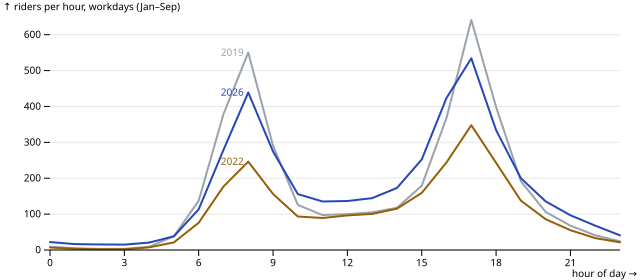

In [7]:
const profile = h
  .filter(pl.col("month").ltEq(9).and(pl.col("workday")).and(pl.col("year").isIn([2019, 2022, 2026])))
  .groupBy(["year", "hour"])
  .agg(pl.col("total").mean().alias("riders"))
  .sort(["year", "hour"]);

Plot.plot({
  document,
  width: 640,
  height: 280,
  marginLeft: 50,
  x: { label: "hour of day", ticks: [0, 3, 6, 9, 12, 15, 18, 21] },
  y: { label: "riders per hour, workdays (Jan–Sep)", grid: true },
  color: { domain: [2019, 2022, 2026], range: ["#9aa3ad", "#94600a", "#2747b8"] },
  marks: [
    Plot.lineY(profile.toRecords(), { x: "hour", y: "riders", stroke: "year", strokeWidth: 2 }),
    Plot.text(profile.filter(pl.col("hour").eq(8)).toRecords(), { x: "hour", y: "riders", text: (r) => String(r.year), dx: -16, fill: "year" }),
    Plot.ruleY([0]),
  ],
})


In [8]:
const hr = pl.col("hour");
const band = pl
  .when(hr.gtEq(6).and(hr.ltEq(9))).then(pl.lit("1 morning 6–10"))
  .when(hr.gtEq(10).and(hr.ltEq(14))).then(pl.lit("2 midday 10–15"))
  .when(hr.gtEq(15).and(hr.ltEq(18))).then(pl.lit("3 evening 15–19"))
  .otherwise(pl.lit("4 night 19–6"));
const bands = h
  .filter(pl.col("month").ltEq(9).and(pl.col("workday")).and(pl.col("year").isIn([2019, 2026])))
  .withColumns(band.alias("band"))
  .groupBy(["year", "band"])
  .agg(pl.col("total").sum().alias("riders"));
const days = d.filter(pl.col("month").ltEq(9).and(pl.col("workday"))).groupBy("year").agg(pl.col("day").count().alias("n"));
const perDay = bands.join(days, { on: "year" }).withColumns(pl.col("riders").div(pl.col("n")).alias("per_day"));
const wide = perDay.filter(pl.col("year").eq(2019)).select("band", pl.col("per_day").alias("y2019"))
  .join(perDay.filter(pl.col("year").eq(2026)).select("band", pl.col("per_day").alias("y2026")), { on: "band" })
  .withColumns(pl.col("y2026").div(pl.col("y2019")).minus(1).mul(100).alias("change_pct"))
  .sort("band");
md(wide)


| band | y2019 | y2026 | change_pct |
| --- | --- | --- | --- |
| 1 morning 6–10 | 1,357 | 1,106 | -19 |
| 2 midday 10–15 | 546 | 745 | 37 |
| 3 evening 15–19 | 1,587 | 1,544 | -3 |
| 4 night 19–6 | 498 | 669 | 34 |

**Finding 4.** The commute has not come back; riding at other hours has. On 2026 workdays the 6–10 am window carries 1,106 riders, 19% fewer than in 2019 (1,357), and the 3–7 pm window is 3% lower. Midday (+37%) and night (+34%) make up the difference. The workday total matches 2019 only because trips moved out of the peaks.

Recorded: ran in the shell, not in this kernel.

```sh
$ curl -sSfo data/seatac.csv "https://www.ncei.noaa.gov/access/services/data/v1?dataset=daily-summaries&stations=USW00024233&startDate=2012-10-01&endDate=2026-09-30&dataTypes=PRCP,TMAX&format=csv&units=metric" && wc -l data/seatac.csv && head -2 data/seatac.csv
```

```text
5114 data/seatac.csv
"STATION","DATE","PRCP","TMAX"
"USW00024233","2012-10-01","0.0","23.3"
```


## 6. Was 2026 just a dry year?

Thomas asked whether weather explains it: a dry year would lift weekend and midday riding most. SeaTac daily rain (NOAA GHCN-Daily, station USW00024233, fetched 9 Nov 2026 by the recorded command above). A day with 1 mm of rain or more counts as wet. Compare the wet-day share by year, then the same splits on dry days only: workdays against weekends, and the workday hour bands from section 5.

In [9]:
import { weather } from "./fremont.ts";
const wx = weather();
const dw = janSep.join(wx, { on: "day" }).withColumns(pl.col("rain_mm").gtEq(1).alias("wet"));

const wetShare = dw
  .filter(pl.col("year").isIn([2019, 2022, 2025, 2026]))
  .groupBy("year")
  .agg(pl.col("wet").mean().mul(100).alias("wet_days_pct"), pl.col("tmax_c").mean().alias("avg_high_c"))
  .sort("year");
md(wetShare, 1)


| year | wet_days_pct | avg_high_c |
| --- | --- | --- |
| 2019 | 31.9 | 17.9 |
| 2022 | 25.6 | 17.2 |
| 2025 | 22.7 | 17.8 |
| 2026 | 23.8 | 17.9 |

In [10]:
const dry = dw
  .filter(pl.col("wet").not().and(pl.col("year").isIn([2019, 2026])))
  .withColumns(pl.when(pl.col("workday")).then(pl.lit("workday")).otherwise(pl.lit("weekend")).alias("kind"))
  .groupBy(["kind", "year"])
  .agg(pl.col("total").mean().alias("per_dry_day"), pl.col("day").count().alias("days"))
  .sort(["kind", "year"]);
md(dry)


| kind | year | per_dry_day | days |
| --- | --- | --- | --- |
| weekend | 2019 | 2,322 | 57 |
| weekend | 2026 | 3,124 | 61 |
| workday | 2019 | 4,474 | 129 |
| workday | 2026 | 4,540 | 147 |

In [11]:
const dryDays = dw.filter(pl.col("wet").not().and(pl.col("workday"))).select("day");
const dryBands = h
  .join(dryDays, { on: "day" })
  .filter(pl.col("year").isIn([2019, 2026]))
  .withColumns(band.alias("band"))
  .groupBy(["year", "band"])
  .agg(pl.col("total").sum().alias("riders"))
  .join(dryDays.join(d, { on: "day" }).groupBy("year").agg(pl.col("day").count().alias("n")), { on: "year" })
  .withColumns(pl.col("riders").div(pl.col("n")).alias("per_day"));
md(
  dryBands.filter(pl.col("year").eq(2019)).select("band", pl.col("per_day").alias("y2019"))
    .join(dryBands.filter(pl.col("year").eq(2026)).select("band", pl.col("per_day").alias("y2026")), { on: "band" })
    .withColumns(pl.col("y2026").div(pl.col("y2019")).minus(1).mul(100).alias("change_pct"))
    .sort("band"),
)


| band | y2019 | y2026 | change_pct |
| --- | --- | --- | --- |
| 1 morning 6–10 | 1,492 | 1,209 | -19 |
| 2 midday 10–15 | 626 | 844 | 35 |
| 3 evening 15–19 | 1,777 | 1,738 | -2 |
| 4 night 19–6 | 578 | 749 | 29 |

**Finding 5.** Weather doesn't explain it. 2026 was drier than 2019 (24% of days wet against 32%), but on dry days alone the pattern holds: weekends 3,124 riders against 2,322 (+35%), workdays 4,540 against 4,474 (+1%). On dry workdays the hour bands match finding 4: the 6–10 am window is 19% below 2019, midday +35%, night +29%.